# Figure 6 · Source reconstruction accuracy and inference time

Local experiment: compare galaxy/source pixels separately from the surrounding
background. Fixed masks come only from the full JWST reference: Gaussian smoothing
(sigma 1 target pixel), a 2-sigma detection threshold using clipped smoothed sky
noise, at least 10 connected pixels, hole filling and a 3-pixel circular dilation.
All detected neighbours are included. Intersect these regions with the identical
validity mask for every method and measure in the central 105×105 pixels.
Thresholds 1.5 and 3 sigma are retained as sensitivity checks, not fitted to rankings.

All 2,118 validation objects and the frozen Figure 5 checkpoints are retained.
Errors use signed physical intensities, with equal weights per object. Main
accuracy panels use source pixels; companion comparisons retain all-pixel and
outside-source errors. The mask preview shows which pixels contribute.
ResNet-D5 denotes the direct-5× residual network.

Accuracy intervals use paired spatial-block resampling. Original inference timings
are reused for unchanged models and sampler; their whiskers are repeat ranges,
not confidence intervals. This notebook only reads saved local artifacts. No W&B
or Overleaf upload. Reference-derived masks can select noise excursions, and the
outside-source region is not guaranteed to be free of faint sources.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Works from the repository root or from paper_figures/.
here = Path.cwd()
workspace = here if (here / 'figure_utils.py').exists() else here / 'paper_figures'
if str(workspace) not in sys.path:
    sys.path.insert(0, str(workspace))
from figure_utils import (ROOT, FIGURES, DATA, COLORS, style, read_json, export,
                          panel, box, arrow, verified_sources, completed_evaluation,
                          run_inventory, sha)
%matplotlib inline
style()
VERSION = 'v03'
BENCHMARK_VERSION = 'v03'  # Reference-defined source/background comparison.

In [2]:
inventory = run_inventory()
inventory['model'] = inventory['model'].replace({'Residual legacy':'ResNet', 'Residual direct 5×':'ResNet-D5'})
display(inventory.drop(columns=['wandb']))
display(Markdown('Checkpoint selection differs: residuals use full-validation masked MAE; '
    'diffusion uses generated physical MAE on a fixed 256-object validation monitor. '
    'Equal update budgets do not match loss, representation, capacity or inference cost.'))

,model,state,epoch,planned_epochs,batch,parameters,validation_monitor,representation,selection
0,ResNet,complete,50,50,8,2332177,2118,linear,masked normalized MAE
1,ResNet-D5,complete,50,50,8,2959953,2118,linear,masked normalized MAE
2,Corrected diffusion,complete,50,50,8,4910593,256,asinh,generated physical MAE


Checkpoint selection differs: residuals use full-validation masked MAE; diffusion uses generated physical MAE on a fixed 256-object validation monitor. Equal update budgets do not match loss, representation, capacity or inference cost.

In [3]:
benchmark_path = FIGURES / 'inputs' / f'model_benchmark_{BENCHMARK_VERSION}.json'
ready = benchmark_path.exists()
if not ready:
    display(Markdown('**Waiting for the matched accuracy and timing benchmark.**'))
else:
    benchmark = read_json(benchmark_path)
    assert benchmark['complete'] and benchmark['split'] == 'validation'
    assert benchmark['units'] == 'MJy/sr'
    object_ids = benchmark['object_ids']
    assert len(set(object_ids)) == len(object_ids) and object_ids
    names = ['bilinear', 'bicubic', 'diffusion', 'diffusion_mean3', 'legacy', 'direct5']
    labels = {'bilinear':'Bilinear', 'bicubic':'Bicubic', 'diffusion':'Diffusion (1 sample)',
              'diffusion_mean3':'Diffusion (mean of 3)', 'legacy':'ResNet', 'direct5':'ResNet-D5'}
    colors = {**COLORS, 'diffusion_mean3':'#B485B8'}
    for name in names:
        values = benchmark['methods'][name]
        assert values['object_ids'] == object_ids
        for key in ['mae_mjy_sr', 'rmse_mjy_sr']:
            arr = np.asarray(values[key])
            assert arr.shape == (len(object_ids),) and np.isfinite(arr).all() and (arr >= 0).all()
        assert values['inference_ms_per_object'] > 0
    mask_path = ROOT / benchmark['source_mask_path']
    assert sha(mask_path) == benchmark['source_mask_sha256']
    mask_protocol = benchmark['source_mask_metadata']['protocol']
    primary = next(r for r in benchmark['source_regions']
                   if r['threshold_sigma'] == mask_protocol['primary_threshold_sigma'])
    source = primary['source']
    background = primary['background']
    assert source['object_ids'] == background['object_ids'] == object_ids
    metrics = source['methods']
    summary = source['summary']['methods']
    coverage = next(c for c in benchmark['source_mask_metadata']['coverage']
                    if c['threshold'] == primary['threshold_sigma'])
    for region in [source, background]:
        for name in names:
            for key in ['mae_mjy_sr', 'rmse_mjy_sr']:
                values = np.asarray(region['methods'][name][key])
                assert values.shape == (len(region['object_ids']),) and np.isfinite(values).all()
    print(f"Source mask: {primary['threshold_sigma']:g} sigma; median area {coverage['median_source_fraction']:.1%}")
    display(pd.DataFrame([dict(method=labels[name],
        source_mae=summary[name]['mae_mjy_sr']['mean'],
        source_rmse=summary[name]['rmse_mjy_sr']['mean'],
        background_mae=background['summary']['methods'][name]['mae_mjy_sr']['mean'],
        background_rmse=background['summary']['methods'][name]['rmse_mjy_sr']['mean'],
        ms_per_object=benchmark['methods'][name]['inference_ms_per_object']) for name in names]))
    print(f"{len(object_ids):,} validation galaxies; {benchmark['summary']['spatial_blocks']} spatial blocks")
    print('Local-only benchmark; no W&B upload.' if benchmark.get('local_only') else 'W&B: '+benchmark['wandb_url'])


Source mask: 2 sigma; median area 18.9%


,method,source_mae,source_rmse,background_mae,background_rmse,ms_per_object
0,Bilinear,0.028902,0.110684,0.013389,0.017103,0.003146
1,Bicubic,0.028897,0.107888,0.014279,0.018246,0.005781
2,Diffusion (1 sample),0.026297,0.081233,0.013916,0.018152,125.307236
3,Diffusion (mean of 3),0.022781,0.069622,0.012050,0.015720,377.986223
4,ResNet,0.020306,0.060173,0.010863,0.013957,0.471671
5,ResNet-D5,0.020247,0.059152,0.010860,0.013985,0.638244


2,118 validation galaxies; 18 spatial blocks
Local-only benchmark; no W&B upload.


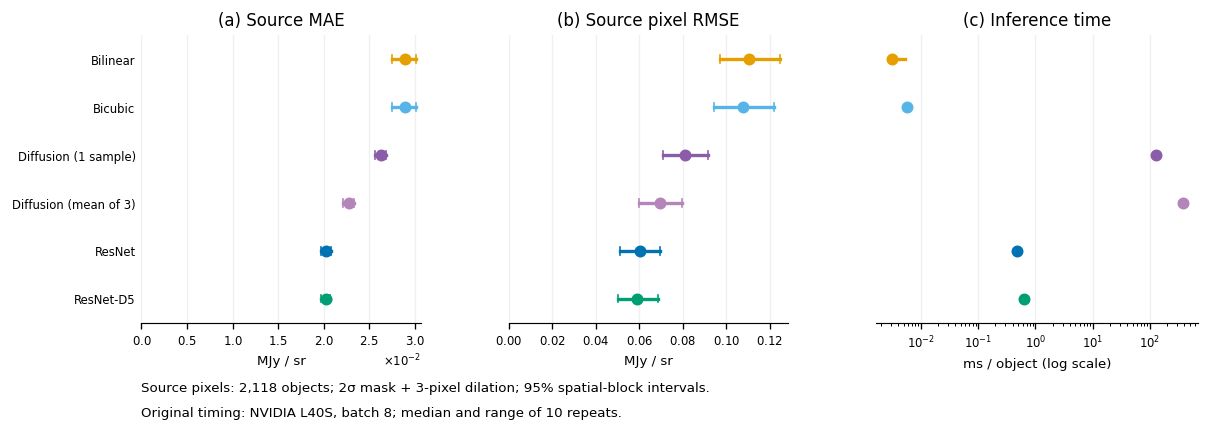

Exported: fig06_model_comparison_v03.pdf, fig06_model_comparison_v03.svg, fig06_model_comparison_v03.png


In [4]:
if ready:
    fig, axes = plt.subplots(1, 3, figsize=(10.8, 3.8), sharey=True,
                             gridspec_kw={'width_ratios':[1,1,1.15]})
    y = np.arange(len(names))
    for ax, key, title in zip(axes[:2], ['mae_mjy_sr', 'rmse_mjy_sr'],
                             ['(a) Source MAE', '(b) Source pixel RMSE']):
        for i, name in enumerate(names):
            record = summary[name][key]
            lo, hi = record['ci95']
            ax.plot([lo,hi],[i,i],color=colors[name],lw=2)
            ax.plot([lo,lo],[i-.08,i+.08],color=colors[name],lw=1)
            ax.plot([hi,hi],[i-.08,i+.08],color=colors[name],lw=1)
            ax.scatter(record['mean'],i,s=38,color=colors[name],zorder=3)
        ax.set_xlim(left=0)
        ax.set_xlabel('MJy / sr')
        ax.set_title(title,fontsize=10)
        ax.ticklabel_format(axis='x',style='sci',scilimits=(-2,2),useMathText=True)
    for i, name in enumerate(names):
        timing = benchmark['methods'][name]['timing']
        lo, hi = timing['min_ms_per_object'],timing['max_ms_per_object']
        axes[2].plot([lo,hi],[i,i],color=colors[name],lw=2)
        axes[2].scatter(timing['median_ms_per_object'],i,s=38,color=colors[name],zorder=3)
    axes[2].set_xscale('log')
    axes[2].set_xlabel('ms / object (log scale)')
    axes[2].set_title('(c) Inference time',fontsize=10)
    axes[0].set_yticks(y,[labels[name] for name in names])
    axes[0].set_ylim(len(names)-.5,-.5)
    for ax in axes:
        ax.grid(axis='x',alpha=.18,zorder=0)
        ax.tick_params(axis='y',length=0)
        ax.spines['left'].set_visible(False)
    fig.subplots_adjust(left=.175,right=.99,top=.88,bottom=.25,wspace=.30)
    fig.text(.175,.10,f"Source pixels: {len(object_ids):,} objects; 2σ mask + 3-pixel dilation; 95% spatial-block intervals.",fontsize=8)
    protocol = benchmark['timing_protocol']
    fig.text(.175,.045,f"Original timing: {protocol['gpu']}, batch {protocol['batch_size']}; median and range of {protocol['repeats']} repeats.",fontsize=8)
    plt.show()
    paths = export(fig, f'fig06_model_comparison_{VERSION}', '06_model_comparison.ipynb',
        [benchmark_path], dict(objects=len(object_ids),methods=names,
        timing=protocol,crop_target_pixels=benchmark['crop_target_pixels'],
        source_mask=mask_protocol, median_source_fraction=coverage['median_source_fraction'],
        accuracy_intervals=benchmark['summary']['rule']),
        status='Local source-masked validation accuracy; original device-resident inference timings')


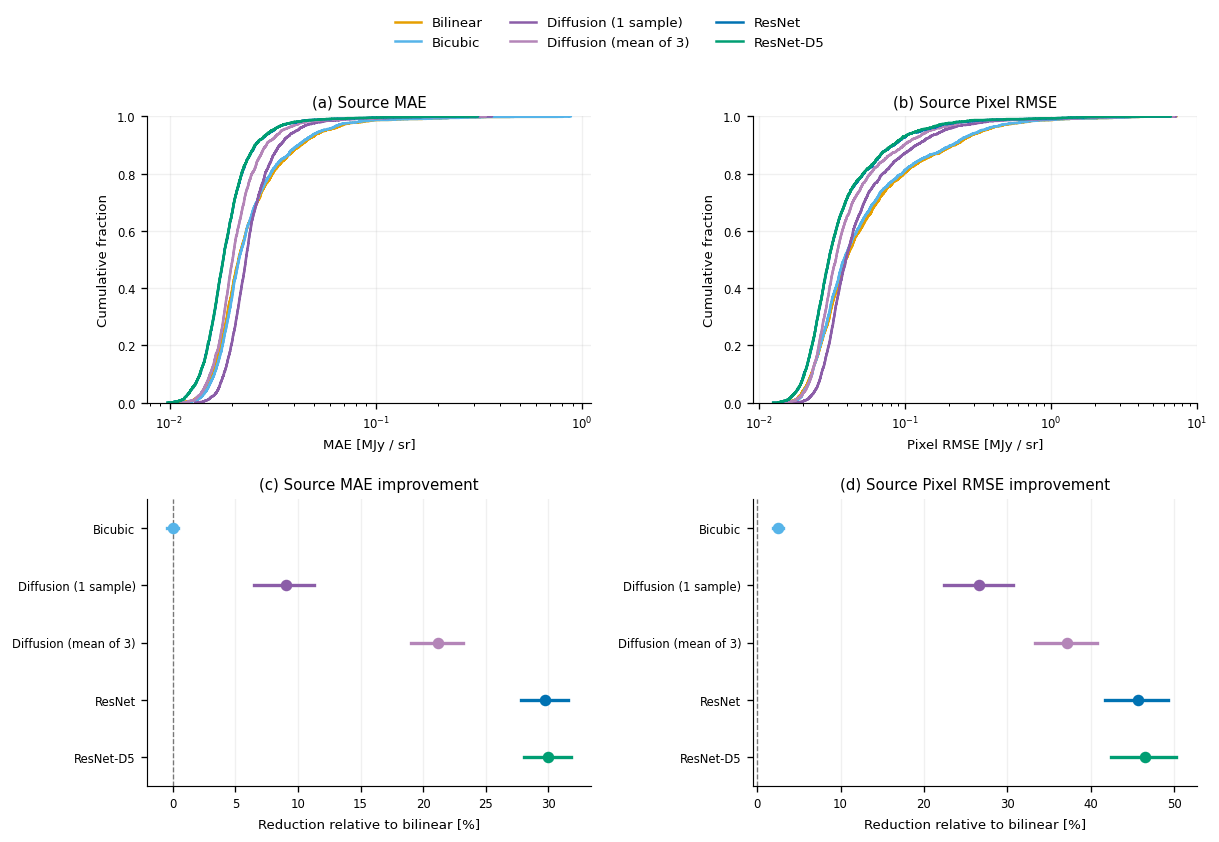

Exported: fig06_error_distributions_v03.pdf, fig06_error_distributions_v03.svg, fig06_error_distributions_v03.png


In [5]:
# Companion distributions and paired gains; no additional inference.
if ready:
    fig, axes = plt.subplots(2,2,figsize=(10.2,7.0))
    for j,(key,title) in enumerate([('mae_mjy_sr','MAE'),('rmse_mjy_sr','Pixel RMSE')]):
        ax=axes[0,j]
        for name in names:
            values=np.sort(metrics[name][key])
            ax.step(values,np.arange(1,len(values)+1)/len(values),where='post',
                    label=labels[name],color=colors[name],lw=1.5)
        ax.set_xscale('log'); ax.set_xlabel(title+' [MJy / sr]')
        ax.set_ylabel('Cumulative fraction');ax.set_ylim(0,1)
        ax.grid(alpha=.18);ax.set_title(f'({chr(97+j)}) Source '+title)
        ax=axes[1,j]
        for i,name in enumerate(names[1:]):
            record=summary[name][key]
            lo,hi=record['gain_ci95_percent']
            ax.plot([lo,hi],[i,i],color=colors[name],lw=2)
            ax.scatter(record['gain_vs_bilinear_percent'],i,color=colors[name],s=35,zorder=3)
        ax.axvline(0,color='#777777',lw=.8,ls='--')
        ax.set_yticks(range(len(names)-1),[labels[n] for n in names[1:]])
        ax.set_ylim(len(names)-1.5,-.5)
        ax.set_xlabel('Reduction relative to bilinear [%]')
        ax.set_title(f'({chr(99+j)}) Source '+title+' improvement')
        ax.grid(axis='x',alpha=.18)
    handles,legend_labels=axes[0,0].get_legend_handles_labels()
    fig.legend(handles,legend_labels,loc='upper center',ncol=3,frameon=False,bbox_to_anchor=(.5,1.0),fontsize=8)
    fig.tight_layout(rect=(0,0,1,.91),h_pad=2,w_pad=2)
    plt.show()
    distribution_paths=export(fig,f'fig06_error_distributions_{VERSION}','06_model_comparison.ipynb',
        [benchmark_path],dict(objects=len(object_ids),methods=names,source_mask=mask_protocol,
        gain='100*(1 - mean per-object method error / mean per-object bilinear error)',
        intervals=benchmark['summary']['rule']),status='Companion matched-error distributions and paired spatial-block gains')


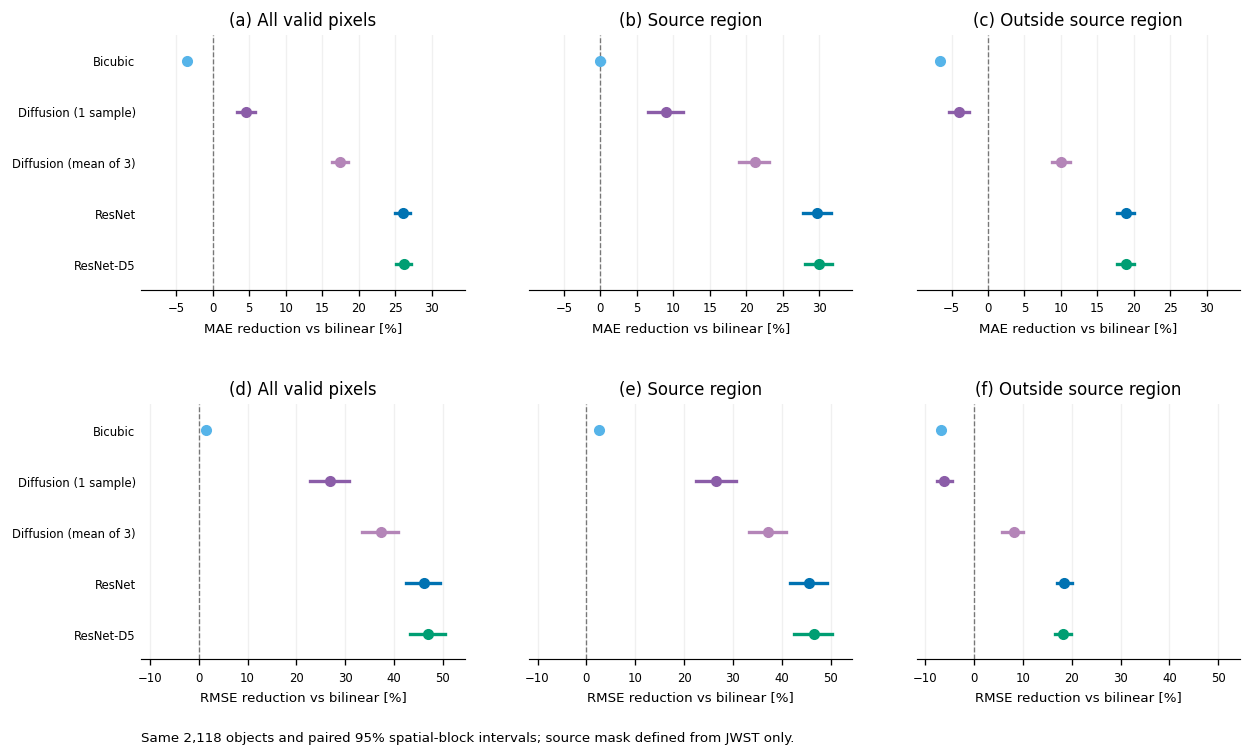

Exported: fig06_source_background_v03.pdf, fig06_source_background_v03.svg, fig06_source_background_v03.png


,threshold_sigma,method,source_mae_gain_pct,source_rmse_gain_pct,background_mae_gain_pct,background_rmse_gain_pct
0,1.5,Bilinear,0.000000,0.000000,0.000000,0.000000
1,1.5,Bicubic,-1.146744,2.207999,-6.759443,-6.790501
2,1.5,Diffusion (1 sample),8.311604,26.942644,-3.851759,-6.113443
3,1.5,Diffusion (mean of 3),20.412707,37.320557,10.259406,8.246817
4,1.5,ResNet,28.786191,45.845003,19.280856,18.728283
5,1.5,ResNet-D5,28.957477,46.765095,19.294857,18.547987
6,2.0,Bilinear,0.000000,0.000000,0.000000,0.000000
7,2.0,Bicubic,0.015603,2.525633,-6.650261,-6.684678
8,2.0,Diffusion (1 sample),9.013307,26.607794,-3.932871,-6.134881
9,2.0,Diffusion (mean of 3),21.179217,37.098480,10.001323,8.081996


In [6]:
# All-pixel, source and outside-source comparisons on the same objects.
if ready:
    fig, axes = plt.subplots(2, 3, figsize=(11.3, 6.5), sharey=True)
    regions = [(benchmark['summary'], 'All valid pixels'),
               (source['summary'], 'Source region'),
               (background['summary'], 'Outside source region')]
    for row, (key, metric) in enumerate([('mae_mjy_sr', 'MAE'), ('rmse_mjy_sr', 'RMSE')]):
        limits = []
        for col, (region_summary, title) in enumerate(regions):
            ax = axes[row, col]
            for i, name in enumerate(names[1:]):
                record = region_summary['methods'][name][key]
                lo, hi = record['gain_ci95_percent']
                limits.extend([lo, hi])
                ax.plot([lo, hi], [i, i], color=colors[name], lw=2)
                ax.scatter(record['gain_vs_bilinear_percent'], i, color=colors[name], s=32, zorder=3)
            ax.axvline(0, color='#777777', lw=.8, ls='--')
            ax.set_yticks(range(len(names)-1), [labels[n] for n in names[1:]])
            ax.set_ylim(len(names)-1.5, -.5)
            ax.set_xlabel(metric+' reduction vs bilinear [%]')
            ax.set_title(f'({chr(97+row*3+col)}) '+title, fontsize=10)
            ax.grid(axis='x', alpha=.18)
            ax.tick_params(axis='y', length=0)
            ax.spines['left'].set_visible(False)
        lo, hi = min(0, min(limits)), max(0, max(limits))
        pad = .07*(hi-lo)
        for ax in axes[row]: ax.set_xlim(lo-pad, hi+pad)
    fig.subplots_adjust(left=.18, right=.99, top=.93, bottom=.13, wspace=.2, hspace=.45)
    fig.text(.18,.025,'Same 2,118 objects and paired 95% spatial-block intervals; source mask defined from JWST only.',fontsize=8)
    plt.show()
    region_paths = export(fig, f'fig06_source_background_{VERSION}', '06_model_comparison.ipynb',
        [benchmark_path], dict(objects=len(object_ids), source_mask=mask_protocol,
        regions=['all_valid','source','outside_source']),
        status='Local source/background diagnostic; positive gain means lower error than bilinear')

    sensitivity = []
    for region in benchmark['source_regions']:
        for name in names:
            row = dict(threshold_sigma=region['threshold_sigma'], method=labels[name])
            for kind in ['source','background']:
                for key, short in [('mae_mjy_sr','mae'),('rmse_mjy_sr','rmse')]:
                    row[kind+'_'+short+'_gain_pct'] = region[kind]['summary']['methods'][name][key]['gain_vs_bilinear_percent']
            sensitivity.append(row)
    display(pd.DataFrame(sensitivity))


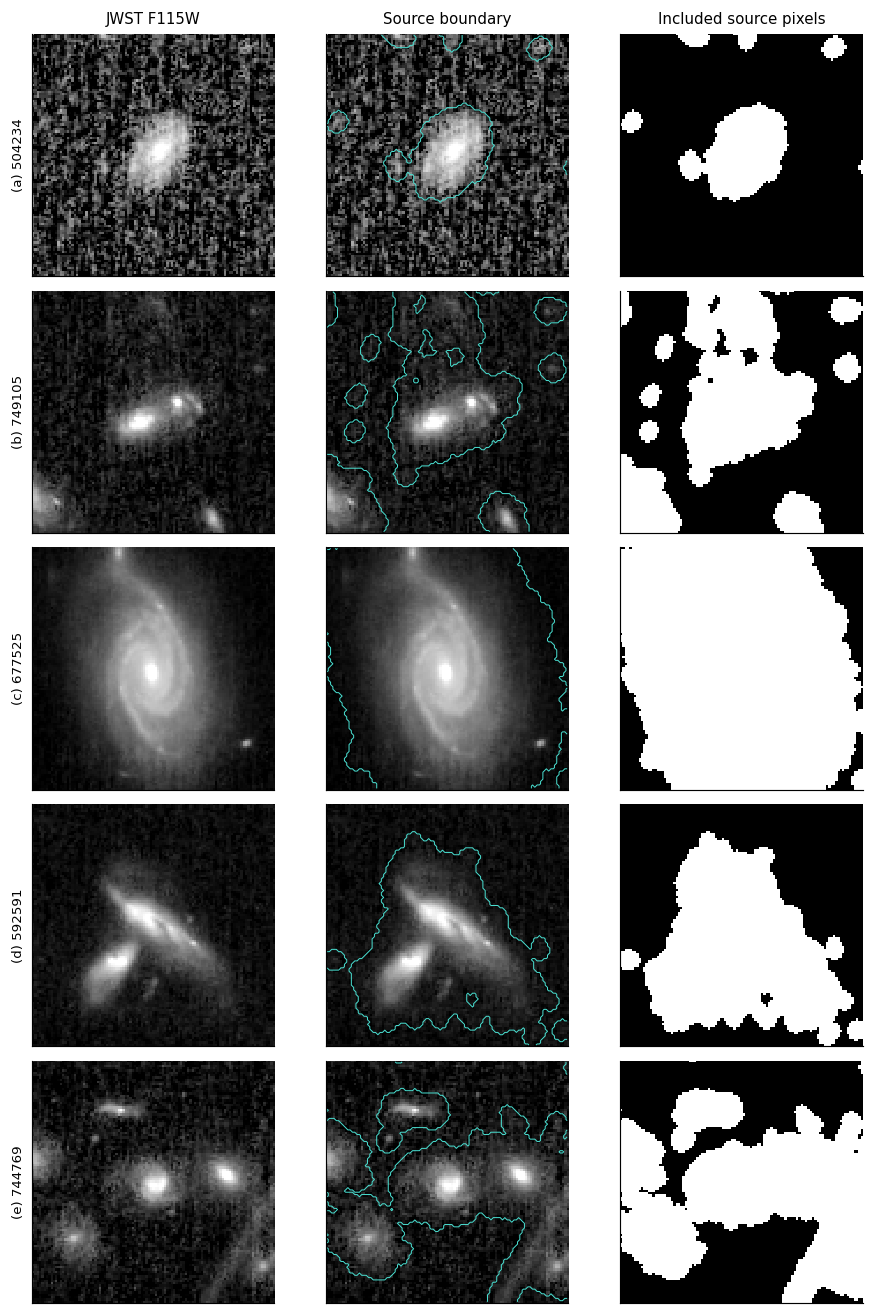

Exported: fig06_source_masks_v03.pdf, fig06_source_masks_v03.svg, fig06_source_masks_v03.png


In [7]:
# Exact masks for the five approved Figure 5 examples, including neighbours.
if ready:
    example_path = FIGURES/'inputs/galaxy_examples_v06.npz'
    example_metadata_path = example_path.with_suffix('.json')
    example_metadata = read_json(example_metadata_path)
    with np.load(example_path) as saved:
        example_ids = saved['object_ids'].tolist()
        references = saved['jwst'].copy()
    with np.load(mask_path) as saved:
        mask_ids = saved['object_ids'].tolist()
        threshold_index = saved['thresholds'].tolist().index(primary['threshold_sigma'])
        selected_masks = saved['source'][[mask_ids.index(oid) for oid in example_ids], threshold_index]
    fig, axes = plt.subplots(len(example_ids), 3, figsize=(7.8, 11))
    for i, oid in enumerate(example_ids):
        target = references[i].squeeze()[50:155,50:155]
        limits = example_metadata['limits_mjy_sr'][i]
        display_image = np.arcsinh(target/limits['stretch'])
        for col, ax in enumerate(axes[i]):
            if col == 2:
                ax.imshow(selected_masks[i], origin='lower', cmap='gray', vmin=0, vmax=1, interpolation='nearest')
            else:
                ax.imshow(display_image, origin='lower', cmap='gray', interpolation='nearest',
                    vmin=np.arcsinh(limits['low']/limits['stretch']), vmax=np.arcsinh(limits['high']/limits['stretch']))
                if col == 1:
                    ax.contour(selected_masks[i],levels=[.5],colors=['#49ded0'],linewidths=.6)
            ax.set_xticks([]); ax.set_yticks([])
            if i == 0: ax.set_title(['JWST F115W','Source boundary','Included source pixels'][col])
        axes[i,0].set_ylabel(f'({chr(97+i)}) {oid}')
    fig.tight_layout()
    plt.show()
    mask_paths = export(fig, f'fig06_source_masks_{VERSION}', '06_model_comparison.ipynb',
        [benchmark_path, mask_path, example_path, example_metadata_path],
        dict(object_ids=example_ids,source_mask=mask_protocol),
        status='Reference-derived source masks for all five approved example fields')


## Working caption

Source reconstruction accuracy and inference time on 2,118 validation objects.
Panels (a) and (b) show the mean of per-object source MAE and pixel RMSE against
JWST F115W in signed, sky-subtracted MJy/sr. Each method uses identical source
pixels within the central 105×105 target-pixel field (~6.3 arcsec). The masks
are detected on the full JWST cutouts after Gaussian smoothing (sigma 1 pixel),
using at least 10 eight-connected pixels above the local clipped sky median
plus twice its smoothed standard deviation, followed by hole filling and a
3-pixel circular dilation. Noise is estimated at radii 70–95 target pixels;
the detection median is used only for mask construction, not subtracted from
images when measuring reconstruction errors. All detected neighbours are included.
Whiskers are 95% percentile intervals from 2,000 paired spatial-block bootstrap
resamples. Each object has equal weight; RMSE is computed before averaging objects.

Panel (c) retains the original median synchronized inference time per object at
batch size eight on an NVIDIA L40S, with min/max of ten repeats after two warmups.
Inputs are device-resident; intensity conversions and diffusion noise generation
are included, while file loading, transfers and evaluation masks/metrics are
excluded. Diffusion uses 50 steps, and its three-sample variant averages linear
images. Checkpoints match Figure 5 (epochs 49 for both residual models, 35 for
diffusion). Accuracy was recomputed at batch size eight; times were not remeasured.

Companion plots show source-error distributions, paired gains for all valid pixels,
source pixels and the outside-source region, and masks for the Figure 5 examples.
Sensitivity results at 1.5 and 3 sigma are saved. All objects have nonempty source
and outside-source regions at all three thresholds. Outside-source pixels may
contain undetected faint light; reference-defined masks can select positive noise
excursions. These are conditional validation comparisons with a noisy reference,
not noise-free reconstruction or calibrated shape measurements. No Figure 6
artifact has been uploaded.
